In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random
import pythonperlin as pp

c:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\pythonperlin\__init__.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution


In [38]:
def terrain_map(size=10, scale=7):
        noise = pp.perlin((size, size), dens=scale)
 
        noise = (noise - noise.min()) / (noise.max() - noise.min())
 
        cmap = plt.cm.colors.LinearSegmentedColormap.from_list(
            "terrain",
            [
                (0.0,  (0.05, 0.2,  0.6)),
                (0.3,  (0.15, 0.45, 0.8)),
                (0.35, (0.8,  0.75, 0.5)),
                (0.45, (0.2,  0.6,  0.2)),
                (0.65, (0.1,  0.4,  0.1)),
                (0.8,  (0.5,  0.4,  0.3)),
                (1.0,  (1.0,  1.0,  1.0)),
            ],
        )
 
        plt.imshow(noise, cmap=cmap)
        plt.axis("off")
        plt.show()


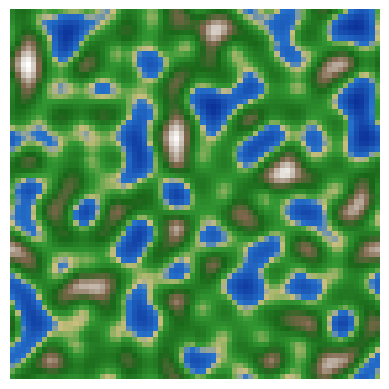

In [41]:
terrain_map()

In [40]:
def koch_iteration(initial, n):
    word = initial
    for _ in range(n):
        word = word.replace("F", "F+F--F+F")
    return word
 
 
def draw_turtle(word, step=5, angle_deg=60):
    angle = np.radians(angle_deg)
    x, y = 0, 0
    direction = 0
    xs, ys = [x], [y]
 
    for character in word:
        if character == "F":
            x += step * np.cos(direction)
            y += step * np.sin(direction)
            xs.append(x)
            ys.append(y)
        elif character == "+":
            direction += angle 
        elif character == "-":
            direction -= angle
 
    return xs, ys

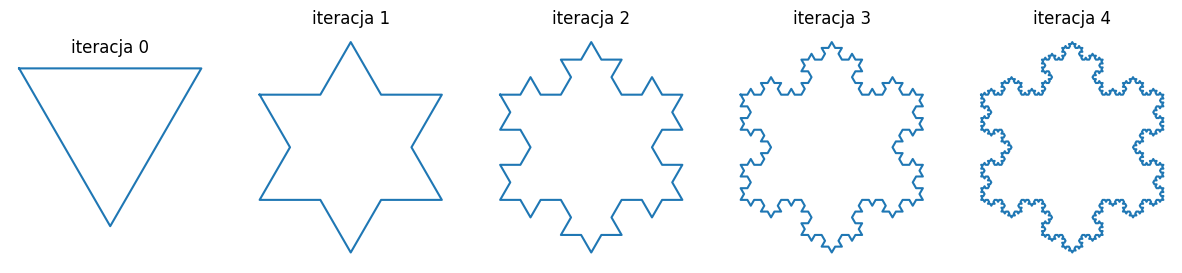

In [45]:
initial = "F--F--F"
fig, axes = plt.subplots(1, 5, figsize=(15, 8))
for i, ax in enumerate(axes):
    word = koch_iteration(initial, i)
    xs, ys = draw_turtle(word)
    ax.plot(xs, ys)
    ax.set_title(f"iteracja {i}")
    ax.set_aspect("equal")
    ax.axis("off")

plt.show()

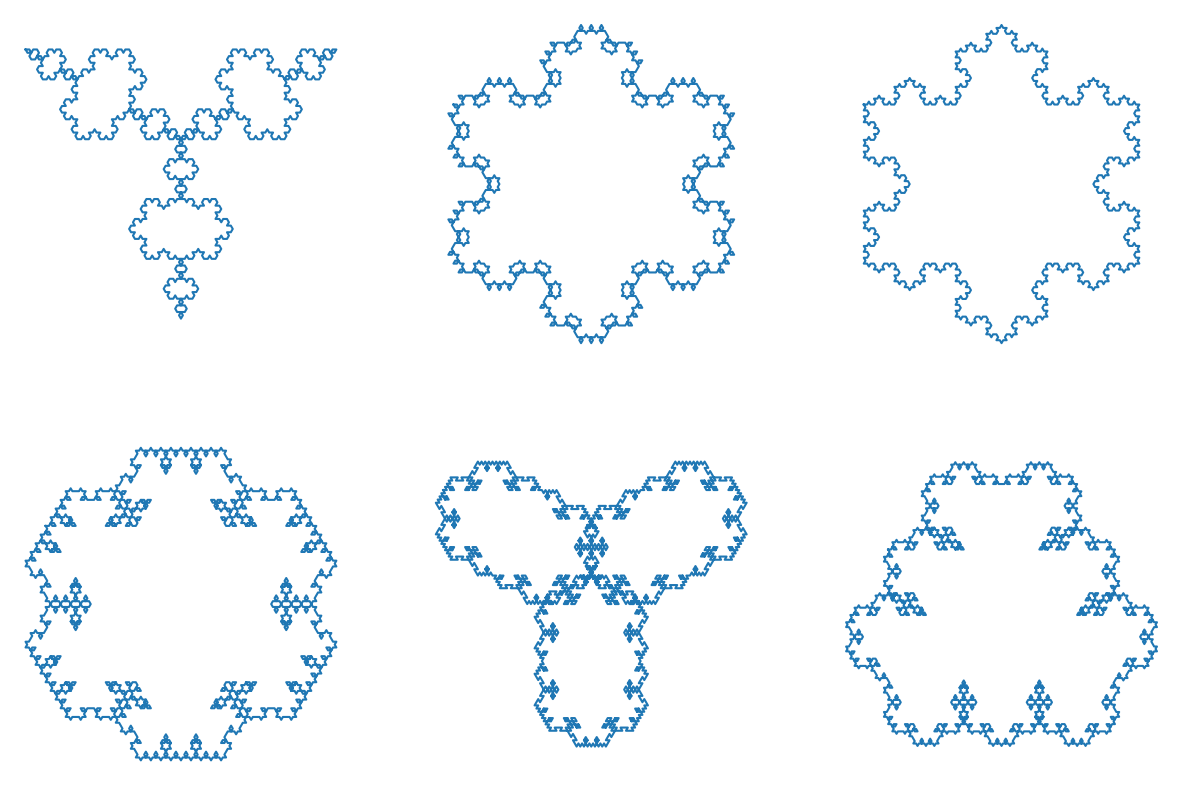

In [51]:
sequences = ["F+F--F+F", "F-F++F-F", "F++F--FF--F++F"]
 
def random_koch_iteration(initial, n):
    word = initial
    for _ in range(n):
        seq = random.choice(sequences)
        word = word.replace("F", seq)
    return word
 
initial = "F--F--F"
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
 
for i, ax in enumerate(axes):
    word = random_koch_iteration(initial, 4)
    xs, ys = draw_turtle(word)
    ax.plot(xs, ys)
    ax.set_aspect("equal")
    ax.axis("off")
 
plt.show()